## 1. Environment setup

# Magnet Power Supply Digital Twin — Dataset Generation

Reproduction support notebook for:

> **"Long Short-Term Memory Networks for Anomaly Detection in Magnet Power Supplies of Particle Accelerators"** (arXiv:2405.18321v1)

This notebook builds a **physics-based simulator** of a magnet power supply (current source + power resistor/coil + heatsink) and uses it to generate a realistic, industrial-style time-series dataset of current, temperature and power.

**Scope of this notebook:** dataset generation only. No LSTM training happens here — this notebook produces the CSV that a downstream training notebook will consume, exactly as in the paper's pipeline (simulate → collect nominal operating data → train on healthy data → detect anomalies via reconstruction/prediction error).

Pipeline implemented here:

1. `CurrentGenerator` — industrial current-profile state machine (0–15 A)
2. `ThermalModel` — first-order RC thermal model solved with Euler integration
3. `PT100Sensor` — realistic sensor model (noise, quantization, delay, resolution)
4. `FaultInjector` — configurable fault-injection primitives (**not** activated for the nominal training dataset — provided for later use in anomaly-detection experiments)
5. `DatasetGenerator` — orchestrates the above into a 48 h @ 1 Hz dataset and writes it to CSV
6. Publication-quality visualization of the generated dataset

All physical parameters are configurable at the top of the `DatasetGenerator` section so the digital twin can be tuned to match a specific magnet power supply.


In [ ]:
# Colab-compatible dependency check / install
import importlib, subprocess, sys

def _ensure(pkg):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for _pkg in ["numpy", "pandas", "scipy", "matplotlib"]:
    _ensure(_pkg)

print("All dependencies available.")

All dependencies available.


In [ ]:
import numpy as np
import pandas as pd
from scipy import signal
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from collections import deque
from dataclasses import dataclass, field
from typing import Optional, Dict, Tuple, List
import datetime as dt

plt.rcParams.update({
    "figure.figsize": (14, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "lines.linewidth": 1.2,
})

RANDOM_SEED = 42  # global seed for full reproducibility of the dataset
print("Setup complete.")

Setup complete.


## 2. `CurrentGenerator` — industrial current-profile state machine

The current fed into the magnet power supply is **never** white noise. Real
accelerator magnet power supplies follow operational cycles: the machine sits
idle, ramps to a working point, holds it for a physics run, steps to a new
setpoint, ramps down, or is driven through repeated load cycles during
commissioning/testing. We reproduce this with a **finite-state machine**
where each state produces a physically coherent current segment of random
(but state-appropriate) duration, and the machine transitions automatically
between states until the full 48 h horizon is filled.

States implemented:

| State | Behaviour |
|---|---|
| `idle` | Near-zero current, small dwell noise |
| `ramp_up` | Linear ramp from current level to a new higher setpoint |
| `hold` | Constant setpoint with small dwell noise (steady operation) |
| `step_change` | Instantaneous step to a new random setpoint |
| `ramp_down` | Linear ramp down towards a low setpoint |
| `random_walk` | Bounded Brownian-motion-like drift (slow manual tuning) |
| `random_load_cycles` | Repeated high/low square-wave load cycling (test/commissioning cycles) |

Current is always clipped to the physical range **0–15 A**.


In [ ]:
class CurrentGenerator:
    """
    Generates a realistic industrial current profile for a magnet power
    supply using a finite-state machine.

    The state machine randomly selects an operating mode (idle, ramp up,
    hold, step change, ramp down, random walk, random load cycling), draws
    a state-appropriate duration, synthesizes the corresponding current
    segment (continuous with the previous segment's end value where
    physically required), and repeats until `total_samples` is filled.

    Parameters
    ----------
    total_samples : int
        Number of 1-Hz samples to generate.
    dt : float
        Sample period in seconds (default 1.0 s -> 1 Hz).
    i_min, i_max : float
        Physical current bounds in Amperes.
    seed : int, optional
        RNG seed for reproducibility.
    """

    STATES = ['idle', 'ramp_up', 'hold', 'step_change',
              'ramp_down', 'random_walk', 'random_load_cycles']

    # (min_duration_s, max_duration_s) per state
    DURATION_RANGES_S = {
        'idle': (60, 1800),
        'ramp_up': (10, 120),
        'hold': (120, 3600),
        'step_change': (5, 30),
        'ramp_down': (10, 120),
        'random_walk': (60, 900),
        'random_load_cycles': (300, 3600),
    }

    # Transition weights bias the machine towards realistic operation
    # (mostly holds/idle, with occasional ramps, steps and test cycles)
    STATE_WEIGHTS = {
        'idle': 0.18,
        'ramp_up': 0.12,
        'hold': 0.32,
        'step_change': 0.10,
        'ramp_down': 0.10,
        'random_walk': 0.10,
        'random_load_cycles': 0.08,
    }

    def __init__(self, total_samples: int, dt: float = 1.0,
                 i_min: float = 0.0, i_max: float = 15.0,
                 seed: Optional[int] = None):
        self.total_samples = int(total_samples)
        self.dt = dt
        self.i_min = i_min
        self.i_max = i_max
        self.rng = np.random.default_rng(seed)
        self._last_value = 0.0
        # log of (start_idx, end_idx, state_name) for traceability / plotting
        self.state_log: List[Tuple[int, int, str]] = []

    # -- duration sampling -------------------------------------------------
    def _random_duration_steps(self, state: str) -> int:
        lo_s, hi_s = self.DURATION_RANGES_S[state]
        lo = max(1, int(lo_s / self.dt))
        hi = max(lo + 1, int(hi_s / self.dt))
        return int(self.rng.integers(lo, hi))

    # -- per-state segment generators --------------------------------------
    def _segment_idle(self, n: int) -> np.ndarray:
        target = self.rng.uniform(0.0, 1.5)
        ramp_len = min(n, max(1, n // 10))
        seg = np.empty(n)
        seg[:ramp_len] = np.linspace(self._last_value, target, ramp_len)
        seg[ramp_len:] = target + self.rng.normal(0, 0.01, n - ramp_len)
        return seg

    def _segment_ramp_up(self, n: int) -> np.ndarray:
        target = self.rng.uniform(5.0, self.i_max)
        return np.linspace(self._last_value, target, n)

    def _segment_hold(self, n: int) -> np.ndarray:
        level = self._last_value
        noise = self.rng.normal(0, 0.04, n)
        return level + noise

    def _segment_step_change(self, n: int) -> np.ndarray:
        target = self.rng.uniform(self.i_min, self.i_max)
        return np.full(n, target)

    def _segment_ramp_down(self, n: int) -> np.ndarray:
        target = self.rng.uniform(0.0, 3.0)
        return np.linspace(self._last_value, target, n)

    def _segment_random_walk(self, n: int) -> np.ndarray:
        steps = self.rng.normal(0, 0.08, n)
        walk = self._last_value + np.cumsum(steps)
        return np.clip(walk, self.i_min, self.i_max)

    def _segment_random_load_cycles(self, n: int) -> np.ndarray:
        period = int(self.rng.integers(max(2, int(30 / self.dt)),
                                        max(3, int(300 / self.dt))))
        high = self.rng.uniform(6.0, self.i_max)
        low = self.rng.uniform(0.0, 3.0)
        t = np.arange(n)
        square = np.where((t // period) % 2 == 0, high, low)
        transition = min(5, period // 4) if period > 4 else 1
        if transition > 0:
            kernel = np.ones(transition) / transition
            square = np.convolve(square, kernel, mode='same')
        return square

    def generate(self) -> np.ndarray:
        """Run the state machine end-to-end and return the current array."""
        dispatch = {
            'idle': self._segment_idle,
            'ramp_up': self._segment_ramp_up,
            'hold': self._segment_hold,
            'step_change': self._segment_step_change,
            'ramp_down': self._segment_ramp_down,
            'random_walk': self._segment_random_walk,
            'random_load_cycles': self._segment_random_load_cycles,
        }
        states = list(self.STATE_WEIGHTS.keys())
        probs = np.array([self.STATE_WEIGHTS[s] for s in states])
        probs = probs / probs.sum()

        current = np.empty(self.total_samples)
        idx = 0
        while idx < self.total_samples:
            state = self.rng.choice(states, p=probs)
            n = self._random_duration_steps(state)
            n = min(n, self.total_samples - idx)
            if n <= 0:
                break
            seg = dispatch[state](n)
            current[idx:idx + n] = seg
            self._last_value = seg[-1]
            self.state_log.append((idx, idx + n, state))
            idx += n

        return np.clip(current, self.i_min, self.i_max)

## 3. `ThermalModel` — first-order thermal RC model

The magnet power supply's power stage is modelled as a single lumped
thermal mass with Joule heating and Newtonian cooling to ambient:

$$C \frac{dT}{dt} = I^2 R - \frac{T - T_{amb}}{R_{th}}$$

where `T` is the component temperature, `Tamb` the ambient temperature,
`R` the electrical resistance, `Rth` the thermal resistance (junction/case
to ambient) and `C` the thermal capacitance. The ODE is integrated with
**explicit (forward) Euler**, `dt = 1 s`, matching the sampling rate of the
dataset:

$$T_{k+1} = T_k + \frac{dt}{C}\Big(I_k^2 R - \frac{T_k - T_{amb,k}}{R_{th}}\Big)$$

`R` and `Rth` are exposed as per-step overrides so the `FaultInjector` can
later modify them (e.g. resistance increase, fan failure) without touching
this class.


In [ ]:
class ThermalModel:
    """
    First-order lumped-parameter thermal model of a magnet power supply
    power stage, integrated with explicit Euler integration.

        C * dT/dt = I^2 * R - (T - Tamb) / Rth

    Parameters
    ----------
    R : float
        Nominal electrical resistance [Ohm].
    Rth : float
        Nominal thermal resistance component-to-ambient [K/W].
    C : float
        Thermal capacitance [J/K].
    T0 : float
        Initial component temperature [degC].
    dt : float
        Integration time step [s]. Must match the sampling interval.
    """

    def __init__(self, R: float = 0.45, Rth: float = 2.2, C: float = 6000.0,
                 T0: float = 25.0, dt: float = 1.0):
        self.R_nominal = R
        self.Rth_nominal = Rth
        self.C = C
        self.T = T0
        self.dt = dt

    def step(self, I: float, Tamb: float,
             R: Optional[float] = None, Rth: Optional[float] = None,
             current_offset: float = 0.0) -> Tuple[float, float]:
        """
        Advance the thermal state by one Euler step.

        Parameters
        ----------
        I : float
            Commanded current at this step [A].
        Tamb : float
            Ambient temperature at this step [degC].
        R, Rth : float, optional
            Per-step overrides for resistance / thermal resistance
            (used by FaultInjector to simulate resistance increase or
            cooling degradation without mutating the nominal parameters).
        current_offset : float
            Additive current offset (used by FaultInjector to simulate a
            current spike fault).

        Returns
        -------
        T : float
            Updated component temperature [degC].
        P : float
            Instantaneous Joule power dissipated [W].
        """
        R_eff = self.R_nominal if R is None else R
        Rth_eff = self.Rth_nominal if Rth is None else Rth
        I_eff = max(0.0, I + current_offset)

        P = (I_eff ** 2) * R_eff
        dTdt = (P - (self.T - Tamb) / Rth_eff) / self.C
        self.T = self.T + dTdt * self.dt
        return self.T, P

    def reset(self, T0: Optional[float] = None):
        """Reset internal temperature state (e.g. between simulation runs)."""
        self.T = self.T if T0 is None else T0

## 4. `PT100Sensor` — virtual temperature sensor

Wraps the "true" simulated temperature with the imperfections of a real
PT100 measurement chain:

- **Gaussian measurement noise** (thermal/electrical noise in the analog
  front end)
- **Measurement delay** (finite thermal response of the probe + sampling
  latency), implemented as a fixed-length ring buffer
- **ADC quantization** (finite bit-depth over the sensor's calibrated
  temperature range)
- **Sensor resolution** (display/logging resolution, applied after
  quantization)

`offset` and `drift` arguments allow the `FaultInjector` to inject sensor
faults later without modifying this class.


In [ ]:
class PT100Sensor:
    """
    Virtual PT100 RTD temperature sensor model.

    Applies (in order): measurement delay -> Gaussian noise -> offset/drift
    (fault hooks) -> ADC quantization -> sensor resolution rounding.

    Parameters
    ----------
    noise_std : float
        Standard deviation of Gaussian measurement noise [degC].
    resolution : float
        Smallest reportable temperature increment [degC].
    delay_steps : int
        Measurement delay expressed in sample steps (thermal lag of the
        probe + acquisition latency).
    adc_bits : int
        ADC resolution in bits over [range_min, range_max].
    range_min, range_max : float
        Calibrated ADC input range [degC].
    seed : int, optional
        RNG seed for reproducibility.
    """

    def __init__(self, noise_std: float = 0.05, resolution: float = 0.01,
                 delay_steps: int = 2, adc_bits: int = 14,
                 range_min: float = -50.0, range_max: float = 250.0,
                 seed: Optional[int] = None):
        self.noise_std = noise_std
        self.resolution = resolution
        self.delay_steps = max(0, int(delay_steps))
        self.adc_bits = adc_bits
        self.range_min = range_min
        self.range_max = range_max
        self.rng = np.random.default_rng(seed)
        self._buffer = deque(maxlen=self.delay_steps + 1)

    def _quantize(self, value: float) -> float:
        levels = 2 ** self.adc_bits
        step = (self.range_max - self.range_min) / levels
        v = np.clip(value, self.range_min, self.range_max)
        code_ = round((v - self.range_min) / step)
        return code_ * step + self.range_min

    def measure(self, true_temp: float, offset: float = 0.0,
                drift: float = 0.0) -> float:
        """
        Produce one measured sample from the current true temperature.

        Parameters
        ----------
        true_temp : float
            Instantaneous true component temperature [degC].
        offset : float
            Additive sensor offset fault [degC] (0 under normal operation).
        drift : float
            Additive sensor drift fault [degC] (0 under normal operation).

        Returns
        -------
        float
            Measured (noisy, delayed, quantized, resolution-limited)
            temperature [degC].
        """
        self._buffer.append(true_temp)
        delayed_temp = self._buffer[0]  # oldest sample in the window = delay
        noisy = delayed_temp + self.rng.normal(0.0, self.noise_std) + offset + drift
        quantized = self._quantize(noisy)
        resolved = round(quantized / self.resolution) * self.resolution
        return resolved

    def reset(self):
        """Clear the internal delay buffer (e.g. between simulation runs)."""
        self._buffer.clear()

## 5. `FaultInjector` — configurable fault primitives (inactive here)

Per the paper's methodology, the LSTM is trained on **healthy / nominal**
operating data only, and anomalies are detected later from the model's
reconstruction/prediction error on unseen (possibly faulty) data. This
notebook therefore **does not activate any fault** in the dataset it
generates — `FaultLabel` will be `0` and `FaultType` will be `"none"` for
every row.

The `FaultInjector` class below implements the fault *mechanisms* so a
downstream (test-set generation) notebook can reuse the exact same
digital twin and simply turn faults on:

| Fault | Physical effect |
|---|---|
| `fan_failure` | Cooling degraded -> `Rth` increases sharply |
| `resistance_increase` | Connector/winding degradation -> `R` increases |
| `current_spike` | Additive current transient superimposed on the profile |
| `sensor_offset` | Constant additive bias on the measured temperature |
| `sensor_drift` | Slowly growing additive bias on the measured temperature |
| `intermittent_cooling` | `Rth` cycles between nominal and degraded (flaky fan) |

Each fault is fully configurable (magnitude, timing window, duty cycle,
etc.) via a `config` dict, and `get_effective_params` returns the
effective `R`, `Rth`, current offset and sensor offset/drift to feed into
`ThermalModel.step` / `PT100Sensor.measure` for a given fault type and
time index.


In [ ]:
class FaultInjector:
    """
    Configurable fault-injection primitives for the magnet power supply
    digital twin. Not used while generating the nominal training dataset;
    provided for downstream anomaly-detection test-set generation.

    Usage
    -----
    >>> fi = FaultInjector(seed=0)
    >>> R_eff, Rth_eff, I_offset, sensor_offset, sensor_drift, active = \\
    ...     fi.get_effective_params('fan_failure', t=1000,
    ...                              t_fault_start=500, t_fault_end=2000,
    ...                              R_nominal=0.45, Rth_nominal=2.2,
    ...                              I_nominal=10.0,
    ...                              config={'rth_factor': 3.0})
    """

    FAULT_TYPES = ['fan_failure', 'resistance_increase', 'current_spike',
                   'sensor_offset', 'sensor_drift', 'intermittent_cooling']

    DEFAULT_CONFIGS = {
        'fan_failure':          {'rth_factor': 2.5},
        'resistance_increase':  {'r_factor': 1.3},
        'current_spike':        {'spike_magnitude': 5.0},
        'sensor_offset':        {'offset_value': 3.0},
        'sensor_drift':         {'drift_rate': 0.002},  # degC per second
        'intermittent_cooling': {'period': 600, 'duty': 0.5, 'rth_factor': 2.0},
    }

    def __init__(self, seed: Optional[int] = None):
        self.rng = np.random.default_rng(seed)

    def get_effective_params(self, fault_type: Optional[str], t: int,
                              t_fault_start: int, t_fault_end: int,
                              R_nominal: float, Rth_nominal: float,
                              I_nominal: float,
                              config: Optional[Dict] = None
                              ) -> Tuple[float, float, float, float, float, bool]:
        """
        Compute the effective plant/sensor parameters at time index `t`
        given an (optionally active) fault.

        Returns
        -------
        R_eff, Rth_eff, current_offset, sensor_offset, sensor_drift, is_active
        """
        cfg = {**self.DEFAULT_CONFIGS.get(fault_type, {}), **(config or {})}
        R_eff, Rth_eff = R_nominal, Rth_nominal
        current_offset, sensor_offset, sensor_drift = 0.0, 0.0, 0.0

        is_active = (fault_type is not None) and (t_fault_start <= t < t_fault_end)
        if not is_active:
            return R_eff, Rth_eff, current_offset, sensor_offset, sensor_drift, False

        if fault_type == 'fan_failure':
            Rth_eff = Rth_nominal * cfg['rth_factor']

        elif fault_type == 'resistance_increase':
            R_eff = R_nominal * cfg['r_factor']

        elif fault_type == 'current_spike':
            current_offset = cfg['spike_magnitude']

        elif fault_type == 'sensor_offset':
            sensor_offset = cfg['offset_value']

        elif fault_type == 'sensor_drift':
            sensor_drift = cfg['drift_rate'] * (t - t_fault_start)

        elif fault_type == 'intermittent_cooling':
            period, duty = cfg['period'], cfg['duty']
            cycle_pos = ((t - t_fault_start) % period) / period
            Rth_eff = Rth_nominal * cfg['rth_factor'] if cycle_pos < duty else Rth_nominal

        else:
            raise ValueError(f"Unknown fault_type: {fault_type}")

        return R_eff, Rth_eff, current_offset, sensor_offset, sensor_drift, True

## 6. `DatasetGenerator` — orchestration

Ties `CurrentGenerator`, `ThermalModel`, `PT100Sensor` and (optionally)
`FaultInjector` together to produce the full 48 h @ 1 Hz dataset:

- **Duration:** 48 h &rarr; 172 800 samples at 1 Hz
- **Ambient temperature:** slow sinusoidal daily cycle, `25 degC +/- 2 degC`
- **Fault injection:** disabled by default (`fault_config=None`) for the
  nominal training dataset, but the method accepts a fault configuration
  for generating labelled anomalous datasets later with the identical
  physics.

Output columns: `Time, Current, AmbientTemperature, TrueTemperature,
MeasuredTemperature, Power, FaultLabel, FaultType`.


In [ ]:
class DatasetGenerator:
    """
    Orchestrates CurrentGenerator, ThermalModel, PT100Sensor and
    FaultInjector to produce a full time-series dataset of a magnet power
    supply's electro-thermal behaviour.

    Parameters
    ----------
    duration_hours : float
        Total simulated duration [h].
    fs_hz : float
        Sampling frequency [Hz]. dt = 1/fs_hz.
    start_time : datetime, optional
        Wall-clock timestamp for sample 0 (used only for the `Time` column).
    thermal_params : dict, optional
        Overrides for ThermalModel(R, Rth, C, T0).
    sensor_params : dict, optional
        Overrides for PT100Sensor(noise_std, resolution, delay_steps,
        adc_bits, range_min, range_max).
    current_params : dict, optional
        Overrides for CurrentGenerator(i_min, i_max).
    ambient_mean_c, ambient_amplitude_c : float
        Mean and +/- amplitude of the sinusoidal daily ambient temperature
        cycle.
    seed : int, optional
        Master seed; sub-seeds are derived deterministically for each
        stochastic component so the whole dataset is fully reproducible.
    """

    def __init__(self,
                 duration_hours: float = 48.0,
                 fs_hz: float = 1.0,
                 start_time: Optional[dt.datetime] = None,
                 thermal_params: Optional[Dict] = None,
                 sensor_params: Optional[Dict] = None,
                 current_params: Optional[Dict] = None,
                 ambient_mean_c: float = 25.0,
                 ambient_amplitude_c: float = 2.0,
                 seed: Optional[int] = 42):
        self.dt = 1.0 / fs_hz
        self.duration_hours = duration_hours
        self.total_samples = int(round(duration_hours * 3600.0 * fs_hz))
        self.start_time = start_time or dt.datetime(2026, 1, 1, 0, 0, 0)

        self.ambient_mean_c = ambient_mean_c
        self.ambient_amplitude_c = ambient_amplitude_c

        master_rng = np.random.default_rng(seed)
        self._seed_current = int(master_rng.integers(0, 2**31 - 1))
        self._seed_sensor = int(master_rng.integers(0, 2**31 - 1))
        self._seed_ambient = int(master_rng.integers(0, 2**31 - 1))
        self._seed_fault = int(master_rng.integers(0, 2**31 - 1))

        self.thermal_params = thermal_params or {}
        self.sensor_params = sensor_params or {}
        self.current_params = current_params or {}

    # -- ambient temperature -------------------------------------------
    def _generate_ambient(self) -> np.ndarray:
        """
        Slowly varying ambient temperature: a 24 h sinusoid (25 +/- 2 degC)
        plus a small amount of slow Gaussian process noise to avoid a
        perfectly periodic (i.e. unrealistic) ambient signal.
        """
        t = np.arange(self.total_samples) * self.dt
        seasonal = self.ambient_amplitude_c * np.sin(2 * np.pi * t / 86400.0 - np.pi / 2)

        rng = np.random.default_rng(self._seed_ambient)
        # low-frequency smooth perturbation via a random-walk filtered with
        # a moving average (keeps the ambient signal slow and smooth)
        raw_walk = np.cumsum(rng.normal(0, 0.002, self.total_samples))
        window = max(1, int(600 / self.dt))
        kernel = np.ones(window) / window
        smooth_walk = np.convolve(raw_walk, kernel, mode='same')
        smooth_walk -= smooth_walk.mean()
        smooth_walk = np.clip(smooth_walk, -0.5, 0.5)

        return self.ambient_mean_c + seasonal + smooth_walk

    # -- main generation --------------------------------------------------
    def generate(self, fault_config: Optional[Dict] = None) -> pd.DataFrame:
        """
        Run the full simulation and return the resulting DataFrame.

        Parameters
        ----------
        fault_config : dict, optional
            If provided, must contain:
              {'fault_type': str, 't_start_h': float, 't_end_h': float,
               'config': dict (optional, fault-specific parameters)}
            If None (default), no fault is injected -> nominal/healthy
            dataset (used for LSTM training, as in the paper).

        Returns
        -------
        pd.DataFrame with columns:
            Time, Current, AmbientTemperature, TrueTemperature,
            MeasuredTemperature, Power, FaultLabel, FaultType
        """
        N = self.total_samples

        # 1) Current profile -------------------------------------------------
        current_gen = CurrentGenerator(
            total_samples=N, dt=self.dt, seed=self._seed_current,
            **self.current_params
        )
        current = current_gen.generate()
        self.current_generator_ = current_gen  # kept for inspection/plots

        # 2) Ambient temperature ---------------------------------------------
        ambient = self._generate_ambient()

        # 3) Thermal + sensor models ------------------------------------------
        thermal = ThermalModel(dt=self.dt, **self.thermal_params)
        sensor = PT100Sensor(seed=self._seed_sensor, **self.sensor_params)
        fault_injector = FaultInjector(seed=self._seed_fault)

        R_nominal = thermal.R_nominal
        Rth_nominal = thermal.Rth_nominal

        # Resolve fault window (sample indices), if any
        if fault_config is not None:
            fault_type = fault_config['fault_type']
            t_start = int(fault_config['t_start_h'] * 3600 / self.dt)
            t_end = int(fault_config['t_end_h'] * 3600 / self.dt)
            fcfg = fault_config.get('config', {})
        else:
            fault_type, t_start, t_end, fcfg = None, -1, -1, {}

        true_temp = np.empty(N)
        measured_temp = np.empty(N)
        power = np.empty(N)
        fault_label = np.zeros(N, dtype=int)
        fault_type_col = np.array(['none'] * N, dtype=object)

        for k in range(N):
            R_eff, Rth_eff, I_offset, sens_off, sens_drift, active = \
                fault_injector.get_effective_params(
                    fault_type, k, t_start, t_end,
                    R_nominal, Rth_nominal, current[k], fcfg
                )

            T, P = thermal.step(current[k], ambient[k], R=R_eff, Rth=Rth_eff,
                                 current_offset=I_offset)
            M = sensor.measure(T, offset=sens_off, drift=sens_drift)

            true_temp[k] = T
            measured_temp[k] = M
            power[k] = P
            if active:
                fault_label[k] = 1
                fault_type_col[k] = fault_type

        # 4) Assemble DataFrame ------------------------------------------------
        timestamps = pd.date_range(start=self.start_time, periods=N,
                                    freq=pd.Timedelta(seconds=self.dt))

        df = pd.DataFrame({
            'Time': timestamps,
            'Current': current,
            'AmbientTemperature': ambient,
            'TrueTemperature': true_temp,
            'MeasuredTemperature': measured_temp,
            'Power': power,
            'FaultLabel': fault_label,
            'FaultType': fault_type_col,
        })

        self.last_dataset_ = df
        return df

## 7. Generate the nominal (healthy) training dataset

48 h at 1 Hz (172 800 samples), **no faults injected** — this matches the
paper's approach of training the LSTM exclusively on nominal operating
data.


In [ ]:
generator = DatasetGenerator(
    duration_hours=48.0,
    fs_hz=1.0,
    thermal_params=dict(R=0.45, Rth=2.2, C=6000.0, T0=25.0),
    sensor_params=dict(noise_std=0.05, resolution=0.01, delay_steps=2,
                        adc_bits=14, range_min=-50.0, range_max=250.0),
    current_params=dict(i_min=0.0, i_max=15.0),
    ambient_mean_c=25.0,
    ambient_amplitude_c=2.0,
    seed=RANDOM_SEED,
)

df = generator.generate(fault_config=None)  # no faults -> nominal dataset

print(f"Generated {len(df):,} samples "
      f"({generator.duration_hours} h at 1 Hz).")
df.head()

Generated 172,800 samples (48.0 h at 1 Hz).


,Time,Current,AmbientTemperature,TrueTemperature,MeasuredTemperature,Power,FaultLabel,FaultType
0,2026-01-01 00:00:00,0.000000,23.015502,24.999850,25.02,0.000000,0,none
1,2026-01-01 00:00:01,0.033147,23.015468,24.999699,25.07,0.000494,0,none
2,2026-01-01 00:00:02,0.066294,23.015434,24.999549,25.11,0.001978,0,none
3,2026-01-01 00:00:03,0.099442,23.015402,24.999400,25.04,0.004450,0,none
4,2026-01-01 00:00:04,0.132589,23.015377,24.999251,25.05,0.007911,0,none


In [ ]:
print(df.describe(include='all').T)
print()
print("FaultLabel value counts (should be all zeros for the nominal dataset):")
print(df['FaultLabel'].value_counts())

                        count unique   top    freq  \
Time                   172800    NaN   NaN     NaN   
Current              172800.0    NaN   NaN     NaN   
AmbientTemperature   172800.0    NaN   NaN     NaN   
TrueTemperature      172800.0    NaN   NaN     NaN   
MeasuredTemperature  172800.0    NaN   NaN     NaN   
Power                172800.0    NaN   NaN     NaN   
FaultLabel           172800.0    NaN   NaN     NaN   
FaultType              172800      1  none  172800   

                                              mean                  min  \
Time                 2026-01-01 23:59:59.500000512  2026-01-01 00:00:00   
Current                                   3.496224                  0.0   
AmbientTemperature                       25.000153            23.013218   
TrueTemperature                          51.092141             24.99565   
MeasuredTemperature                      51.091358                24.87   
Power                                    13.482484             

## 8. Export dataset to CSV

In [ ]:
OUTPUT_PATH = "magnet_power_supply_dataset_nominal.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved dataset to: {OUTPUT_PATH}")
print(f"File size: {__import__('os').path.getsize(OUTPUT_PATH) / (1024*1024):.2f} MB")

Saved dataset to: magnet_power_supply_dataset_nominal.csv
File size: 17.83 MB


## 9. Visualization

Publication-quality plots of the generated dataset: current, temperature
(true vs. measured), ambient temperature and power dissipation.


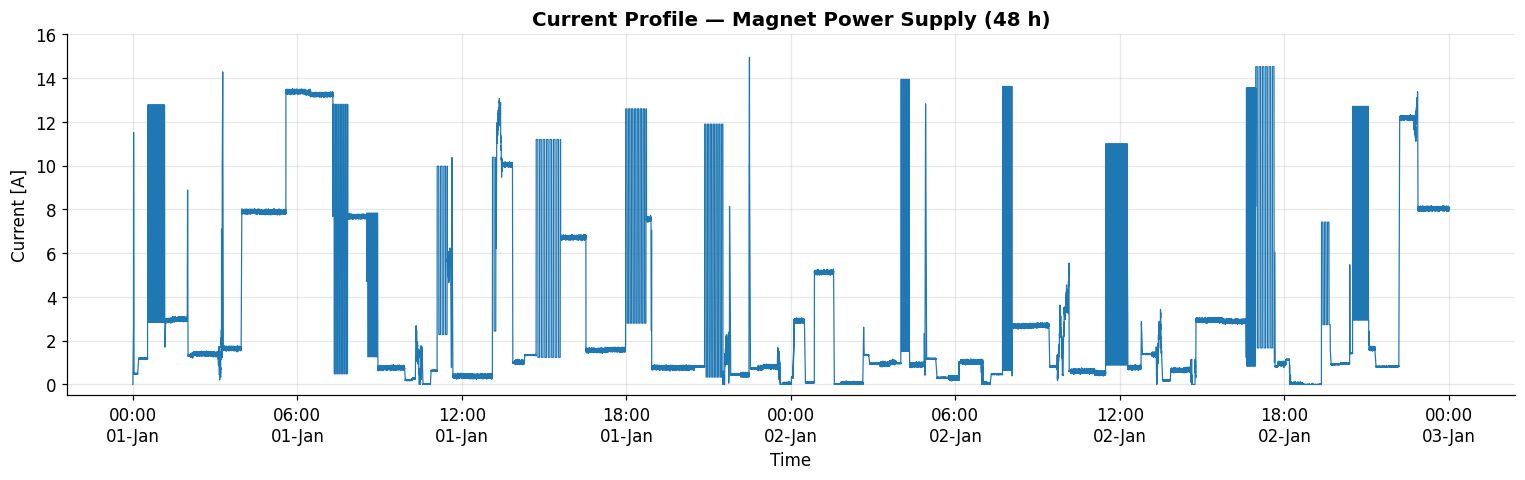

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df['Time'], df['Current'], color='#1f77b4', linewidth=0.8)
ax.set_title('Current Profile — Magnet Power Supply (48 h)')
ax.set_xlabel('Time')
ax.set_ylabel('Current [A]')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d-%b'))
ax.set_ylim(-0.5, 16)
fig.tight_layout()
plt.show()

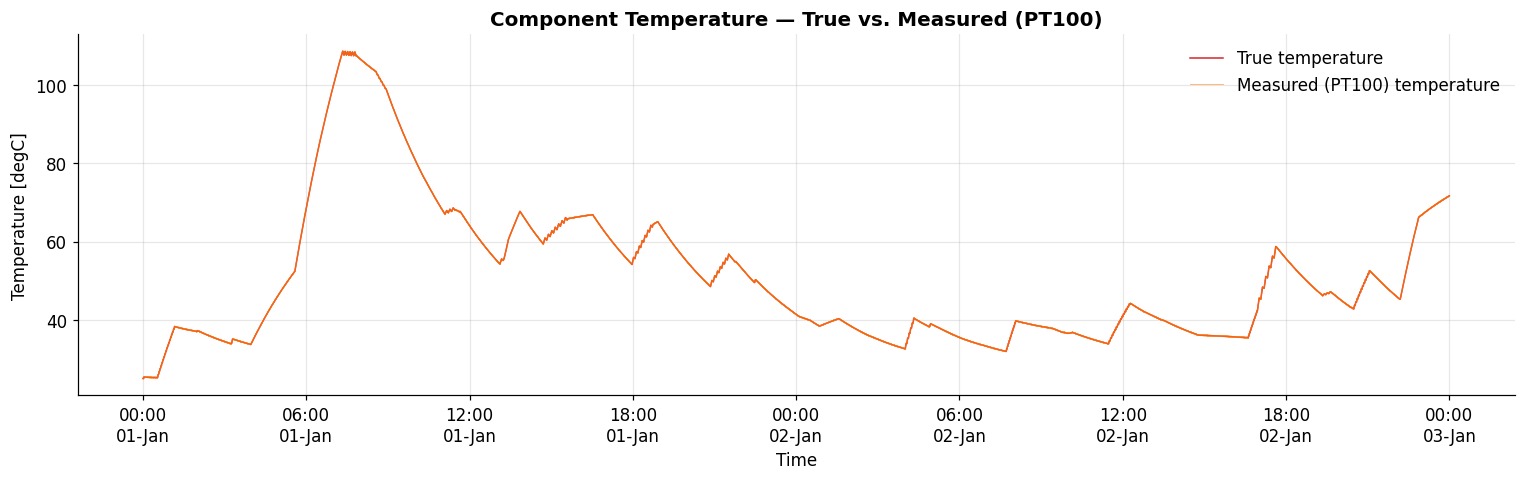

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df['Time'], df['TrueTemperature'], color='#d62728',
        linewidth=1.0, label='True temperature')
ax.plot(df['Time'], df['MeasuredTemperature'], color='#ff7f0e',
        linewidth=0.5, alpha=0.7, label='Measured (PT100) temperature')
ax.set_title('Component Temperature — True vs. Measured (PT100)')
ax.set_xlabel('Time')
ax.set_ylabel('Temperature [degC]')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d-%b'))
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
plt.show()

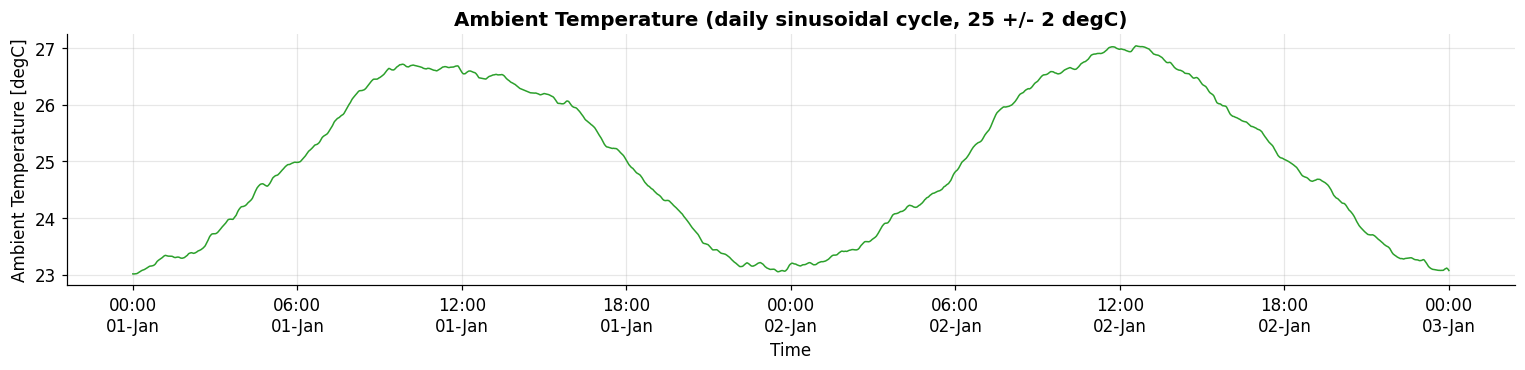

In [ ]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(df['Time'], df['AmbientTemperature'], color='#2ca02c', linewidth=1.0)
ax.set_title('Ambient Temperature (daily sinusoidal cycle, 25 +/- 2 degC)')
ax.set_xlabel('Time')
ax.set_ylabel('Ambient Temperature [degC]')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d-%b'))
fig.tight_layout()
plt.show()

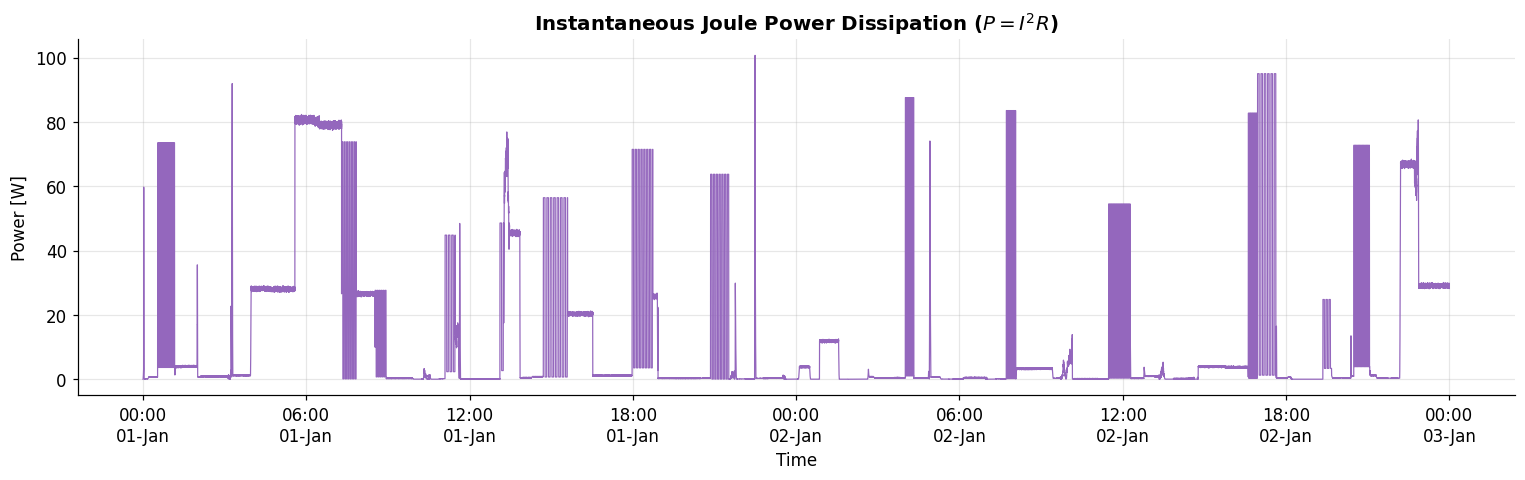

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df['Time'], df['Power'], color='#9467bd', linewidth=0.8)
ax.set_title('Instantaneous Joule Power Dissipation ($P = I^2 R$)')
ax.set_xlabel('Time')
ax.set_ylabel('Power [W]')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d-%b'))
fig.tight_layout()
plt.show()

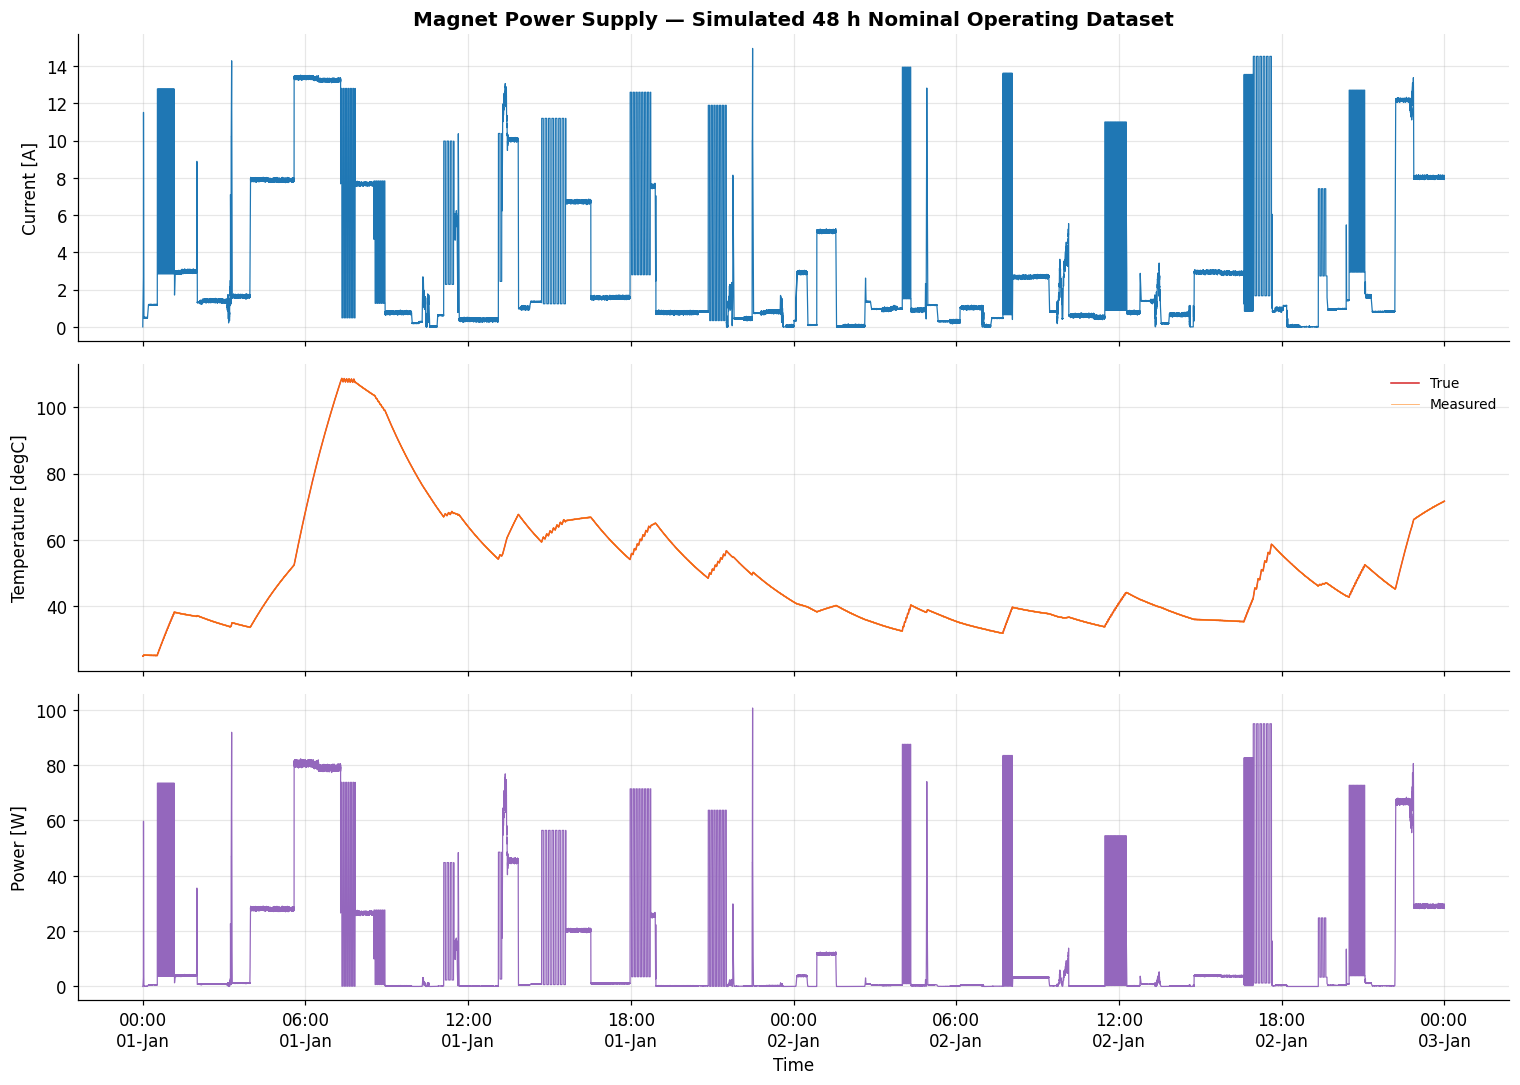

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df['Time'], df['Current'], color='#1f77b4', linewidth=0.8)
axes[0].set_ylabel('Current [A]')
axes[0].set_title('Magnet Power Supply — Simulated 48 h Nominal Operating Dataset')

axes[1].plot(df['Time'], df['TrueTemperature'], color='#d62728',
             linewidth=1.0, label='True')
axes[1].plot(df['Time'], df['MeasuredTemperature'], color='#ff7f0e',
             linewidth=0.5, alpha=0.7, label='Measured')
axes[1].set_ylabel('Temperature [degC]')
axes[1].legend(loc='upper right', frameon=False, fontsize=9)

axes[2].plot(df['Time'], df['Power'], color='#9467bd', linewidth=0.8)
axes[2].set_ylabel('Power [W]')
axes[2].set_xlabel('Time')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d-%b'))

fig.tight_layout()
plt.show()

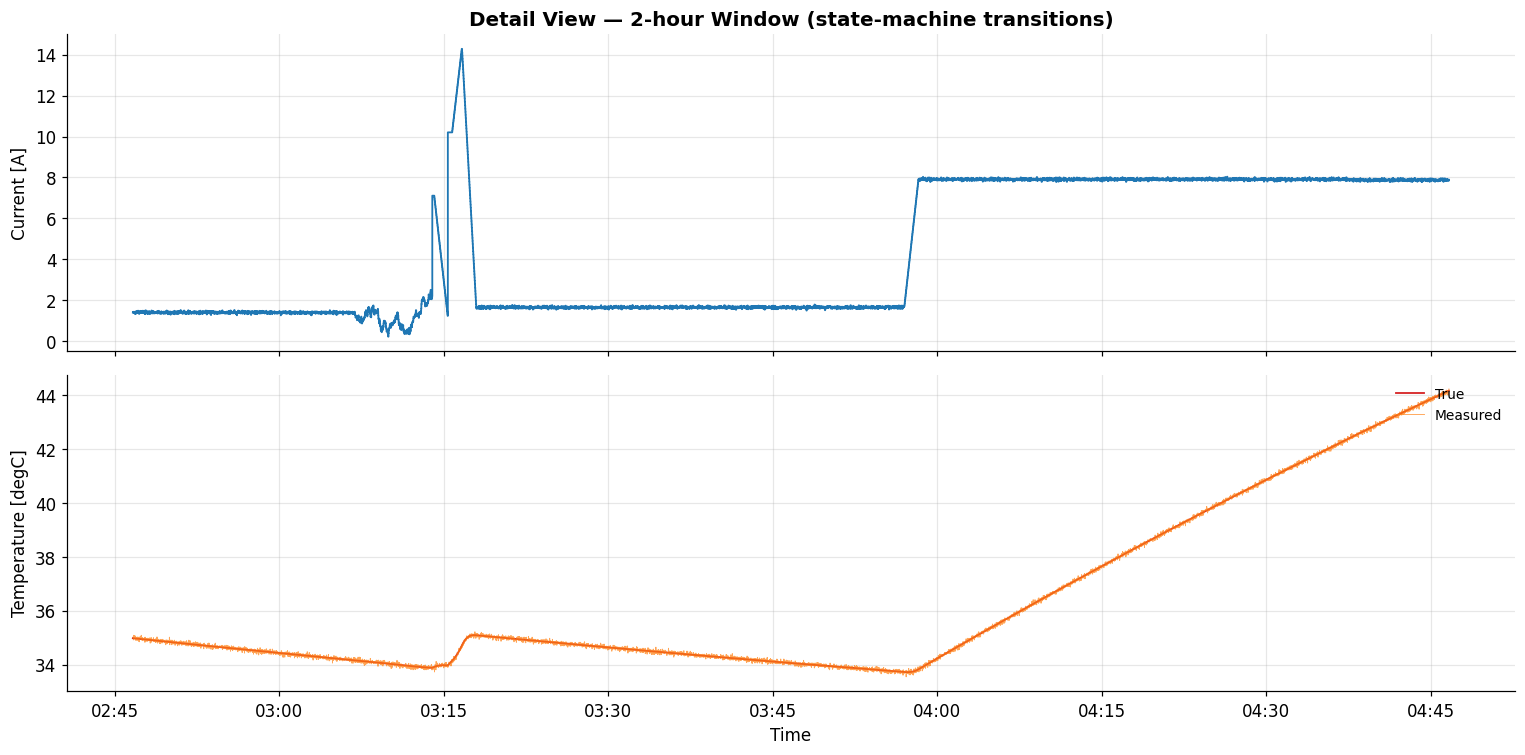

In [ ]:
# Zoom-in on a 2-hour window to inspect the current state-machine
# transitions and the corresponding thermal response in detail.
window = df.iloc[10000:17200]  # 2 hours

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].step(window['Time'], window['Current'], color='#1f77b4', where='post')
axes[0].set_ylabel('Current [A]')
axes[0].set_title('Detail View — 2-hour Window (state-machine transitions)')

axes[1].plot(window['Time'], window['TrueTemperature'], color='#d62728', label='True')
axes[1].plot(window['Time'], window['MeasuredTemperature'], color='#ff7f0e',
             alpha=0.7, linewidth=0.6, label='Measured')
axes[1].set_ylabel('Temperature [degC]')
axes[1].set_xlabel('Time')
axes[1].legend(loc='upper right', frameon=False, fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

fig.tight_layout()
plt.show()

## 10. Sanity checks

Quick numerical sanity checks confirming the physics and bounds are
respected before this dataset is used for LSTM training in a follow-up
notebook.


In [ ]:
assert df['Current'].between(0, 15).all(), "Current out of physical bounds!"
assert (df['FaultLabel'] == 0).all(), "Nominal dataset must have no faults!"
assert (df['FaultType'] == 'none').all(), "Nominal dataset must have FaultType == 'none'!"
assert len(df) == 172800, "Expected 172,800 samples (48h @ 1Hz)!"
assert df['Time'].is_monotonic_increasing, "Timestamps must be monotonic!"

# Steady-state consistency check: at max sustained current, temperature
# should trend towards I^2*R*Rth above ambient (first-order RC behaviour).
print("Sanity checks passed.")
print(f"Current range:  [{df['Current'].min():.3f}, {df['Current'].max():.3f}] A")
print(f"True temp range: [{df['TrueTemperature'].min():.2f}, {df['TrueTemperature'].max():.2f}] degC")
print(f"Measured temp range: [{df['MeasuredTemperature'].min():.2f}, {df['MeasuredTemperature'].max():.2f}] degC")
print(f"Power range: [{df['Power'].min():.2f}, {df['Power'].max():.2f}] W")

Sanity checks passed.
Current range:  [0.000, 14.957] A
True temp range: [25.00, 108.74] degC
Measured temp range: [24.87, 108.81] degC
Power range: [0.00, 100.67] W


## Next steps

This notebook produced `magnet_power_supply_dataset_nominal.csv` — a
48 h @ 1 Hz, fault-free dataset suitable for training the LSTM
autoencoder / predictor described in the paper on **nominal** operating
behaviour.

A follow-up notebook (not included here, per the requested scope) would:

1. Reuse this exact `DatasetGenerator` with a non-`None` `fault_config` to
   generate labelled anomalous test sets (using `FaultInjector`'s six
   fault types already implemented above).
2. Build and train the LSTM architecture from the paper on the nominal
   dataset (sequence windowing, train/val split, TensorFlow/PyTorch).
3. Evaluate anomaly detection performance (reconstruction/prediction
   error thresholding) on the faulty test sets.
